   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
Da

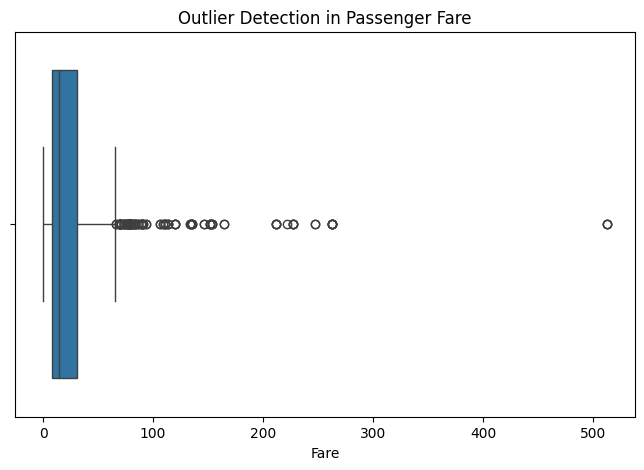

Gender categories:
Sex
male      577
female    314
Name: count, dtype: int64

Boarding port categories:
Embarked
S    646
C    168
Q     77
Name: count, dtype: int64
Gender values: ['male' 'female']
Boarding port values: ['S' 'C' 'Q']
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name   Age  SibSp  Parch  \
0                            Braund, Mr. Owen Harris  22.0      1      0   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  38.0      1      0   
2                             Heikkinen, Miss. Laina  26.0      0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  35.0      1      0   
4                           Allen, Mr. William Henry  35.0      0      0   

             Ticket     Fare  Sex_female  Sex_male  Embarked_C  Embarked_Q  \
0         A/5

In [8]:
import pandas as pd

df = pd.read_csv('/content/train (1).csv')

print(df.head())
print("Dataset shape:", df.shape)

print("Number of rows:", df.shape[0])

print("Number of columns:", df.shape[1])
print("Missing values in each column:")
print(df.isnull().sum())
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nColumn Names:")
print(df.columns.tolist())
# Create a copy of the original dataset
df_clean = df.copy()

# Fill missing ages using the median
df_clean["Age"] = df_clean["Age"].fillna(
    df_clean["Age"].median()
)

# Fill missing boarding ports using the most common value
df_clean["Embarked"] = df_clean["Embarked"].fillna(
    df_clean["Embarked"].mode()[0]
)

# Remove the Cabin column
df_clean = df_clean.drop(columns=["Cabin"])

# Check missing values after cleaning
print("Missing values after cleaning:")
print(df_clean.isnull().sum())
print(
    "Duplicate rows before cleaning:",
    df_clean.duplicated().sum()
)

df_clean = df_clean.drop_duplicates()

print(
    "Duplicate rows after cleaning:",
    df_clean.duplicated().sum()
)
Q1 = df_clean["Fare"].quantile(0.25)
Q3 = df_clean["Fare"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_clean[
    (df_clean["Fare"] < lower_bound) |
    (df_clean["Fare"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

print("Number of potential outliers:", len(outliers))
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(x=df_clean["Fare"])

plt.title("Outlier Detection in Passenger Fare")
plt.xlabel("Fare")

plt.show()
print("Gender categories:")
print(df_clean["Sex"].value_counts())

print("\nBoarding port categories:")
print(df_clean["Embarked"].value_counts())
df_clean["Sex"] = df_clean["Sex"].str.strip().str.lower()

df_clean["Embarked"] = (
    df_clean["Embarked"].str.strip().str.upper()
)

print("Gender values:", df_clean["Sex"].unique())

print("Boarding port values:", df_clean["Embarked"].unique())
df_preprocessed = pd.get_dummies(
    df_clean,
    columns=["Sex", "Embarked"],
    dtype=int
)

print(df_preprocessed.head())
df_preprocessed["FamilySize"] = (
    df_preprocessed["SibSp"]
    + df_preprocessed["Parch"]
    + 1
)

print(
    df_preprocessed[
        ["SibSp", "Parch", "FamilySize"]
    ].head()
)
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

df_preprocessed[["Age", "Fare"]] = scaler.fit_transform(
    df_preprocessed[["Age", "Fare"]]
)

print(df_preprocessed[["Age", "Fare"]].head())

df_clean.to_csv(
    "/content/titanic_cleaned.csv",
    index=False
)

df_preprocessed.to_csv(
    "/content/titanic_preprocessed.csv",
    index=False
)

print("Datasets saved successfully!")

print("Cleaned dataset shape:", df_clean.shape)

print(
    "Preprocessed dataset shape:",
    df_preprocessed.shape
)
